# Fig 6. What the PM2.5-O3 coupling is

(a) How much of the PM2.5-O3 partial correlation each candidate confounder accounts for (change in r, with its interval).
(b) The same partial correlation, r(PM2.5, O3 | NO2, NO), inside terciles of temperature.
(c) The same quantity inside terciles of other conditioners.

**Review fixes (2026-09-21):** (R2) all intervals are 95 % moving-block-bootstrap intervals (30-day blocks), because days are
autocorrelated (lag-1 ~ 0.77, effective N ~ 385 of 2916); (R3) panels (b) and (c) now plot the *plain* partial correlation r(PM2.5, O3 | controls),
the same quantity as (a), not the correlation of a PM2.5 x radiation interaction term (that version is Fig S13).
Data: canonical sample of notebook T1_T2 (N = 2916).

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from style import *

In [2]:
# Settings (edit here, then Run All)
# Portrait layout (2026-09-24): (a) full width, (b) full width below it, then the 5 conditioner panels
# of (c) as a 2-column x 3-row grid (one slot spare, used for the shared legend) -- pages are taller than
# wide, and the old (11.5, 8.8) side-by-side layout squeezed everything into an 8pt font. Panels (c)-(g)
# replace the old single "(c)" label shared by all five conditioner panels.
S = dict(figsize=(8.6, 13.5), hspace=0.6, wspace=0.5, height_ratios=(1.05, 0.85, 1.7),
         forest_marker="o", forest_ms=6.5, forest_lw=1.8,        # panel (a)
         bar_width=0.55, cap=3.5,                                # panel (b)
         line_marker="o", line_ms=4.5, line_lw=1.8, ci_alpha=0.6,   # panels (c)-(g)
         fontsize=10.5, xlim=(0.0, 0.88), text_x=0.745)
CONTROL_SETS = {"no2+no": ("controls NO$_2$ + NO", NAVY, "-", "o", None),
                "legacy w700+lts+day_of_week": ("controls w$_{700}$ + LTS + weekday", GREY, "--", "o", "white")}
COLOURS = dict(accounts=NAVY, rises=RED, none=GREY)          # (a): CI of the change excludes 0 (falls / rises) or not

In [3]:
# Data
att = pd.read_csv(DATA_OUT / "mechanism_attenuation_canonical.csv")
cond = pd.read_csv(DATA_OUT / "conditioning_terciles_canonical.csv")
trend = pd.read_csv(DATA_OUT / "tercile_trend_tests_canonical.csv")
raw = att.iloc[0]; N = int(raw.n)

saved /path/to/project/Paper/figures/fig06_mechanisms.png


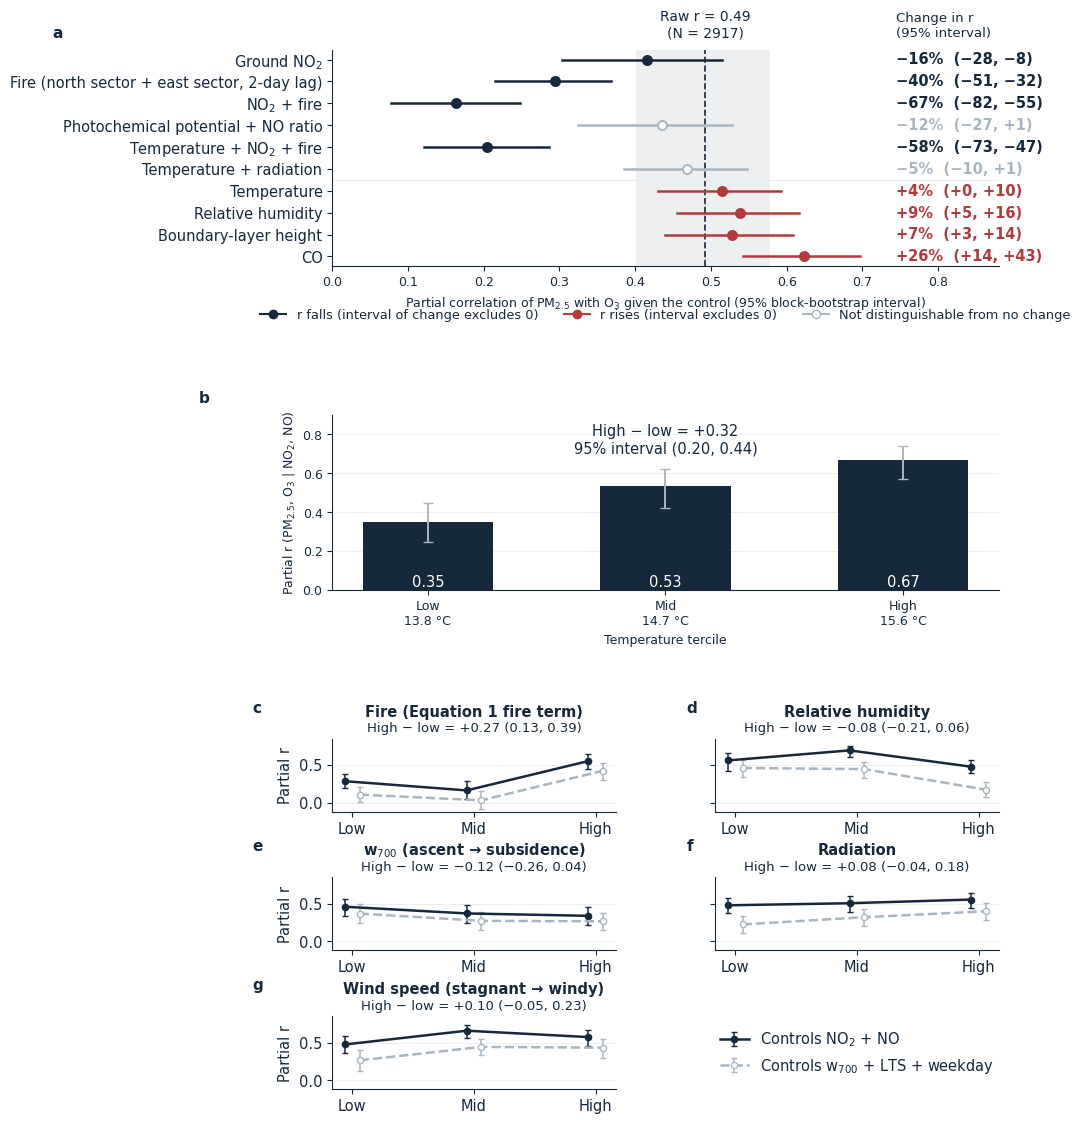

In [4]:
# Figure
fig = plt.figure(figsize=S["figsize"])
gs = GridSpec(3, 2, figure=fig, height_ratios=list(S["height_ratios"]), hspace=S["hspace"], wspace=S["wspace"])

# ---- (a) forest ---------------------------------------------------------------
axa = fig.add_subplot(gs[0, :])
order = ["ground NO2", "fire", "NO2 + fire", "photochemical_potential + no_ratio", "temperature + NO2 + fire", "temperature + radiation",
         "temperature (temp_2m)", "RH (rh_2m)", "BLH (blh_mean)", "CO"]
labels = {"ground NO2": "ground NO$_2$", "fire": "fire (north sector + east sector, 2-day lag)", "NO2 + fire": "NO$_2$ + fire",
          "photochemical_potential + no_ratio": "photochemical potential + NO ratio", "temperature + NO2 + fire": "temperature + NO$_2$ + fire",
          "temperature + radiation": "temperature + radiation", "temperature (temp_2m)": "temperature", "RH (rh_2m)": "relative humidity",
          "BLH (blh_mean)": "boundary-layer height", "CO": "CO"}
key = {"ground NO2": "NO2 (ground)", "fire": "fire (Eq. 1 fire term", "NO2 + fire": "NO2 + fire"}
def find(k):
    for c in att.control:
        if c.startswith(k) or k in c: return att[att.control == c].iloc[0]
rows = [(k, find(key.get(k, k))) for k in order]
y = np.arange(len(rows))[::-1]
axa.axvline(raw.partial_r, color=NAVY, lw=1.2, ls="--")
axa.axvspan(raw.ci_lo, raw.ci_hi, color=NAVY, alpha=0.07, lw=0)
axa.text(raw.partial_r, len(rows) - 0.1, f"raw r = {raw.partial_r:.2f}\n(N = {N})", ha="center", va="bottom", fontsize=S["fontsize"] - 0.5)
def minus(v): return f"{v:+.0f}".replace("-", "−")
for yi, (k, r) in zip(y, rows):
    kind = "accounts" if r.pct_ci_lo > 0 else ("rises" if r.pct_ci_hi < 0 else "none")
    col = COLOURS[kind]
    axa.plot([r.ci_lo, r.ci_hi], [yi, yi], color=col, lw=S["forest_lw"])
    axa.plot(r.partial_r, yi, S["forest_marker"], color=col, ms=S["forest_ms"], mfc="white" if kind == "none" else col, mew=1.4)
    axa.text(S["text_x"], yi, f"{minus(-r.pct_attenuation)}%  ({minus(-r.pct_ci_hi)}, {minus(-r.pct_ci_lo)})", va="center", ha="left",
             fontsize=S["fontsize"], color=col, fontweight="bold")
axa.set_yticks(y); axa.set_yticklabels([labels[k] for k, _ in rows], fontsize=S["fontsize"])
axa.set_xlim(*S["xlim"]); axa.set_xlabel("partial correlation of PM$_{2.5}$ with O$_3$ given the control (95% block-bootstrap interval)")
axa.text(S["text_x"], len(rows) - 0.1, "change in r\n(95% interval)", fontsize=S["fontsize"] - 1, ha="left", va="bottom")
axa.axhline(3.5, color=LIGHT, lw=0.8)
from matplotlib.lines import Line2D
axa.legend(handles=[Line2D([], [], marker="o", color=COLOURS["accounts"], ls="-", label="r falls (interval of change excludes 0)"),
                    Line2D([], [], marker="o", color=COLOURS["rises"], ls="-", label="r rises (interval excludes 0)"),
                    Line2D([], [], marker="o", color=COLOURS["none"], mfc="white", ls="-", label="not distinguishable from no change")],
           frameon=False, fontsize=S["fontsize"] - 1.2, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
panel_label(axa, "a", x=-0.42)

# ---- (b) temperature terciles, plain partial r -------------------------------------
axb = fig.add_subplot(gs[1, :])
t = cond[(cond.conditioner == "temp_2m") & (cond.control_set == "no2+no")]
x = np.arange(3); v = t.partial_r_pm25_only.to_numpy(); lo = t.ci_lo_pm25_only.to_numpy(); hi = t.ci_hi_pm25_only.to_numpy()
axb.bar(x, v, S["bar_width"], color=NAVY, zorder=3)
axb.errorbar(x, v, yerr=[v - lo, hi - v], fmt="none", ecolor=GREY, lw=1.4, capsize=S["cap"], zorder=4)
for xi, vi in zip(x, v): axb.text(xi, 0.02, f"{vi:.2f}", ha="center", fontsize=S["fontsize"], color="white", zorder=5)
tr = trend[(trend.conditioner == "temp_2m") & (trend.control_set == "no2+no") & (trend.quantity == "pm25_only")].iloc[0]
axb.text(0.5, 0.95, f"high − low = {tr.high_minus_low:+.2f}\n95% interval ({tr.ci_lo:.2f}, {tr.ci_hi:.2f})", transform=axb.transAxes, ha="center", va="top", fontsize=S["fontsize"])
axb.set_xticks(x); axb.set_xticklabels([f"{r.tercile}\n{r.conditioner_mean:.1f} °C" for r in t.itertuples()])
axb.set_xlabel("temperature tercile"); axb.set_ylabel("partial r (PM$_{2.5}$, O$_3$ | NO$_2$, NO)")
axb.set_ylim(0, 0.9); axb.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
panel_label(axb, "b", x=-0.2, y=1.05)

# ---- (c)-(g) other conditioners, plain partial r, as a 2-column x 3-row grid ----------
# (2026-09-24: was 5 panels crammed side by side under one shared "(c)" label; now each gets
# its own letter and the freed-up width goes to bigger fonts. The spare 6th grid slot holds
# the shared legend instead of an awkward bbox_to_anchor beneath one arbitrary panel.)
specs = [("fire_eq1", "fire (Eq. 1 fire term)", "c"), ("rh_2m", "relative humidity", "d"),
         ("w700", "w$_{700}$ (ascent → subsidence)", "e"), ("radiation_mean", "radiation", "f"),
         ("wind_speed", "wind speed (stagnant → windy)", "g")]
inner_c = gs[2, :].subgridspec(3, 2, hspace=0.9, wspace=0.35)
legend_handles = None
for k, (col, ttl, letter) in enumerate(specs):
    r, c = divmod(k, 2)
    ax = fig.add_subplot(inner_c[r, c]); xs = np.arange(3)
    for cs, (lab, cc, ls, mk, mfc) in CONTROL_SETS.items():
        a = cond[(cond.conditioner == col) & (cond.control_set == cs)].set_index("tercile").loc[["low", "mid", "high"]]
        off = -0.06 if cs == "no2+no" else 0.06
        ax.errorbar(xs + off, a.partial_r_pm25_only, yerr=[a.partial_r_pm25_only - a.ci_lo_pm25_only, a.ci_hi_pm25_only - a.partial_r_pm25_only],
                    fmt=S["line_marker"], color=cc, ms=S["line_ms"], mfc=mfc or cc, lw=S["line_lw"], ls=ls,
                    ecolor=cc, elinewidth=1.1, capsize=S["cap"] - 1, alpha=1, label=lab)
    tr = trend[(trend.conditioner == col) & (trend.control_set == "no2+no") & (trend.quantity == "pm25_only")].iloc[0]
    ax.set_title(f"{ttl}", fontsize=S["fontsize"], fontweight="bold", pad=16)
    ax.text(0.5, 1.05, f"high − low = {tr.high_minus_low:+.2f} ({tr.ci_lo:.2f}, {tr.ci_hi:.2f})".replace("-", "−"), transform=ax.transAxes, ha="center", va="bottom", fontsize=S["fontsize"] - 1)
    ax.set_xticks(xs); ax.set_xticklabels(["low", "mid", "high"], fontsize=S["fontsize"]); ax.set_ylim(-0.12, 0.85)
    ax.tick_params(axis="y", labelsize=S["fontsize"])
    if c == 0: ax.set_ylabel("partial r", fontsize=S["fontsize"])
    else: ax.set_yticklabels([])
    ax.grid(axis="y", color=LIGHT, lw=0.6)
    panel_label(ax, letter, x=-0.28 if c == 0 else -0.1, y=1.32)
    if legend_handles is None: legend_handles = ax.get_legend_handles_labels()
axl = fig.add_subplot(inner_c[2, 1]); axl.axis("off")
axl.legend(*legend_handles, frameon=False, fontsize=S["fontsize"], loc="center")
save_fig(fig, "fig06_mechanisms")